## Домашнее задание №1 | Вариант 5


Выполнил:

### 1. NumPy

In [1]:
import numpy as np


1. Создайте единичную матрицу размером 3х3

In [2]:
print(np.eye(3, dtype=int))


[[1 0 0]
 [0 1 0]
 [0 0 1]]


2. Создайте кастомный dtype который описывает цвет состоящий из 4х unsigned bytes(RGBA пиксель)

In [3]:
rgba_dtype = np.dtype([('R', 'u1'), ('G', 'u1'), ('B', 'u1'), ('A', 'u1')])
pixel = np.array((255, 128, 0, 255), dtype=rgba_dtype)
print('dtype:', rgba_dtype)
print('Пиксель RGBA:', pixel)


dtype: [('R', 'u1'), ('G', 'u1'), ('B', 'u1'), ('A', 'u1')]
Пиксель RGBA: (255, 128, 0, 255)


3. Как игнорировать все numpy warnings(не рекомендуем к использованию)?

In [4]:
old_settings = np.seterr(all='ignore')
print(np.geterr())
np.seterr(**old_settings)


{'divide': 'ignore', 'over': 'ignore', 'under': 'ignore', 'invalid': 'ignore'}


{'divide': 'ignore', 'over': 'ignore', 'under': 'ignore', 'invalid': 'ignore'}

4. Создайте случайный вектор размера 10 и отсортируйте его

In [5]:
rng = np.random.default_rng(42)
v = rng.random(10)
print(np.sort(v))


[0.09417735 0.12811363 0.43887844 0.45038594 0.69736803 0.7611397
 0.77395605 0.78606431 0.85859792 0.97562235]


5. Создайте read-only массив(неизменяемый)

In [6]:
a = np.arange(5)
a.flags.writeable = False
print(a, a.flags.writeable)


[0 1 2 3 4] False


6. Рассмотрим случайную матрицу размером 10х2, представляющую декартовы координаты, преобразуем их в полярные координаты

In [7]:
xy = rng.normal(size=(10, 2))
r = np.hypot(xy[:, 0], xy[:, 1])
phi = np.arctan2(xy[:, 1], xy[:, 0])
polar = np.column_stack((r, phi))
print(' x       y       r       phi (рад)')
print(np.round(np.column_stack((xy, polar)), 3))


 x       y       r       phi (рад)
[[ 0.879  0.778  1.174  0.724]
 [ 0.066  1.127  1.129  1.512]
 [ 0.468 -0.859  0.978 -1.073]
 [ 0.369 -0.959  1.027 -1.204]
 [ 0.878 -0.05   0.88  -0.057]
 [-0.185 -0.681  0.706 -1.836]
 [ 1.223 -0.155  1.232 -0.126]
 [-0.428 -0.352  0.554 -2.454]
 [ 0.532  0.365  0.646  0.602]
 [ 0.413  0.431  0.597  0.807]]


7. Создайте структурированный массив с координатами x и y, охватывающий область [0,1]x[0,1]

In [8]:
grid = np.linspace(0, 1, 5)
xg, yg = np.meshgrid(grid, grid)
coords = np.empty(xg.size, dtype=[('x', 'f8'), ('y', 'f8')])
coords['x'] = xg.ravel()
coords['y'] = yg.ravel()
print(coords.reshape(5, 5))


[[(0.  , 0.  ) (0.25, 0.  ) (0.5 , 0.  ) (0.75, 0.  ) (1.  , 0.  )]
 [(0.  , 0.25) (0.25, 0.25) (0.5 , 0.25) (0.75, 0.25) (1.  , 0.25)]
 [(0.  , 0.5 ) (0.25, 0.5 ) (0.5 , 0.5 ) (0.75, 0.5 ) (1.  , 0.5 )]
 [(0.  , 0.75) (0.25, 0.75) (0.5 , 0.75) (0.75, 0.75) (1.  , 0.75)]
 [(0.  , 1.  ) (0.25, 1.  ) (0.5 , 1.  ) (0.75, 1.  ) (1.  , 1.  )]]


8. Учитывая два массива X и Y, постройте матрицу Коши $C$ ($C_{ij} =\frac{1}{x_i - y_j}$)

In [9]:
x = rng.normal(size=5)
y = rng.normal(size=5)
C = 1 / (x[:, None] - y[None, :])
print('x =', np.round(x, 3))
print('y =', np.round(y, 3))
print('Матрица Коши C:')
print(np.round(C, 3))


x = [ 2.142 -0.406 -0.512 -0.814  0.616]
y = [ 1.129 -0.114 -0.84  -0.824  0.651]
Матрица Коши C:
[[  0.987   0.443   0.335   0.337   0.671]
 [ -0.651  -3.419   2.306   2.392  -0.946]
 [ -0.609  -2.511   3.05    3.203  -0.86 ]
 [ -0.515  -1.429  37.902  93.384  -0.683]
 [ -1.949   1.37    0.687   0.694 -28.891]]


9. Как конвертировать массив float(32 bit) к массиву целых чисел (integer 32 bit) in place?

In [10]:
f = np.array([1.0, -2.8, 3.5], dtype=np.float32)
ints = f.view(np.int32)
ints[:] = f.astype(np.int32)
f.dtype = np.int32
print(f, f.dtype)


[ 1 -2  3] int32


10. Как случайно заменить p элементов в 2D массиве?

In [11]:
A = np.arange(20).reshape(4, 5)
p = 6
idx = rng.choice(A.size, size=p, replace=False)
replacement = rng.integers(100, 200, size=p)
A.ravel()[idx] = replacement
print('Индексы:', idx)
print(A)


Индексы: [11 19  2 17  6 14]
[[  0   1 138   3   4]
 [  5 128   7   8   9]
 [ 10 180  12  13 123]
 [ 15  16 189  18 184]]


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Классический начальный набор данных - данные пассажиров титаника.

Файл: `data.csv`

```
PassangerId - уникальный номер пассажира
Survived - выжил человек или нет
Pclass - класс обслуживания
Name - имя человека, обращение к ней/нему
Sex - пол человека
Age - возраст на момент крушения
SibSp - количество братьев и сестер / супругов на борту "Титаника"
Parch - количество родителей / детей на борту "Титаника"
Ticket - номер билета
Fare - стоимость проезда для пассажиров
Cabin - каюта
Embarked - причал отбытия. C = Cherbourg Q = Queenstown S = Southampton
```


In [12]:
import pandas as pd


In [13]:
df = pd.read_csv('data.csv')
print(df.shape)
print(df.head())
df.info()
print('Пропусков в Age:', df['Age'].isna().sum())


(891, 12)
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN    

1. Узнайте сколько было на борту человек

In [14]:
print('Пассажиров в таблице:', len(df))


Пассажиров в таблице: 891


2. Какой медианный и средний возраста пассажиров

In [15]:
print('Медиана:', df['Age'].median())
print('Среднее:', round(df['Age'].mean(), 2))


Медиана: 28.0
Среднее: 29.7


3. Посчитайте процент выживаемости детей(до 16 лет) и взрослых

In [16]:
print('Дети:', f"{df.loc[df['Age'] < 16, 'Survived'].mean():.1%}")
print('Взрослые:', f"{df.loc[df['Age'] >= 16, 'Survived'].mean():.1%}")


Дети: 59.0%
Взрослые: 38.2%


4. Верна ли гипотеза, что женщины и дети сажались в шлюпки первыми и выживали больше?

In [17]:
print('Выживаемость по полу, %:')
print(df.groupby('Sex')['Survived'].mean().mul(100).round(1))
print('Дети до 16, %:', round(df.loc[df['Age'] < 16, 'Survived'].mean() * 100, 1))
print('Женщины и дети выживали чаще мужчин. Порядок посадки в шлюпки из этих данных не известен.')


Выживаемость по полу, %:
Sex
female    74.2
male      18.9
Name: Survived, dtype: float64
Дети до 16, %: 59.0
Женщины и дети выживали чаще мужчин. Порядок посадки в шлюпки из этих данных не известен.


5. Зависит ли выживаемость от класса обслуживания?

In [18]:
print(df.groupby('Pclass')['Survived'].agg(['count', 'mean']))
print('В первом классе доля выживших выше, чем во втором и третьем.')


        count      mean
Pclass                 
1         216  0.629630
2         184  0.472826
3         491  0.242363
В первом классе доля выживших выше, чем во втором и третьем.


6. Посчитайте средний возраст умерших женщин и мужчин

In [19]:
print(df.loc[df['Survived'] == 0].groupby('Sex')['Age'].mean().round(2))


Sex
female    25.05
male      31.62
Name: Age, dtype: float64


7. Различается ли процент выживаемости пассажиров с хотя бы одним родственником на борту и одиночек?

In [20]:
has_family = df['SibSp'] + df['Parch'] > 0
print(df.groupby(has_family)['Survived'].agg(['count', 'mean']))
print('С родственниками выживали чаще.')


       count      mean
False    537  0.303538
True     354  0.505650
С родственниками выживали чаще.


8. Различается ли средняя стоимость билета у умерших и выживших пассажиров?

In [21]:
print(df.groupby('Survived')['Fare'].mean().round(2))
print('У выживших средняя цена билета выше.')


Survived
0    22.12
1    48.40
Name: Fare, dtype: float64
У выживших средняя цена билета выше.


9. Выведите максимальный и минимальный возраст выживших пассажиров во 2 классе обслуживания

In [22]:
ages = df.loc[(df['Survived'] == 1) & (df['Pclass'] == 2), 'Age']
print('Минимум:', ages.min(), 'Максимум:', ages.max())


Минимум: 0.67 Максимум: 62.0


10. Подтвердите или опровергните гипотезу: молодым мужчинам(от 18 лет) выжить легче, чем более взрослым

In [23]:
young = df.loc[(df['Sex'] == 'male') & df['Age'].between(18, 29), 'Survived']
older = df.loc[(df['Sex'] == 'male') & (df['Age'] >= 30), 'Survived']
print(f'18–29 лет: {young.mean():.1%}, n={len(young)}')
print(f'30+ лет: {older.mean():.1%}, n={len(older)}')
print('Гипотеза не подтвердилась для границы 30 лет.')


18–29 лет: 15.6%, n=179
30+ лет: 19.4%, n=216
Гипотеза не подтвердилась для границы 30 лет.


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Постройте гистограмму распределения возростов пассажиров

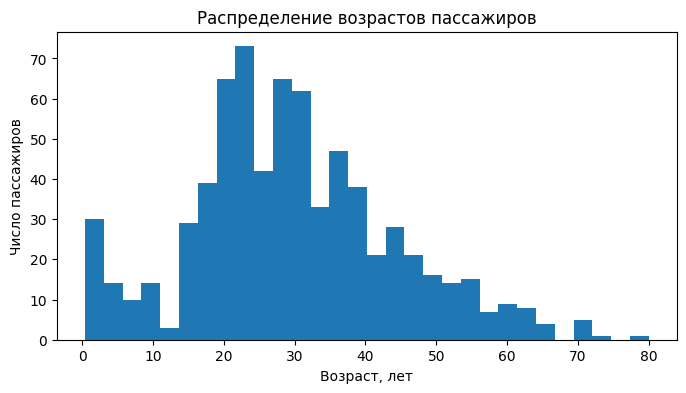

In [24]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
plt.hist(df['Age'].dropna(), bins=30)
plt.title('Распределение возрастов пассажиров')
plt.xlabel('Возраст, лет')
plt.ylabel('Число пассажиров')
plt.show()


2. Постройте гистограммы распределения цен для пассажиров разных классов

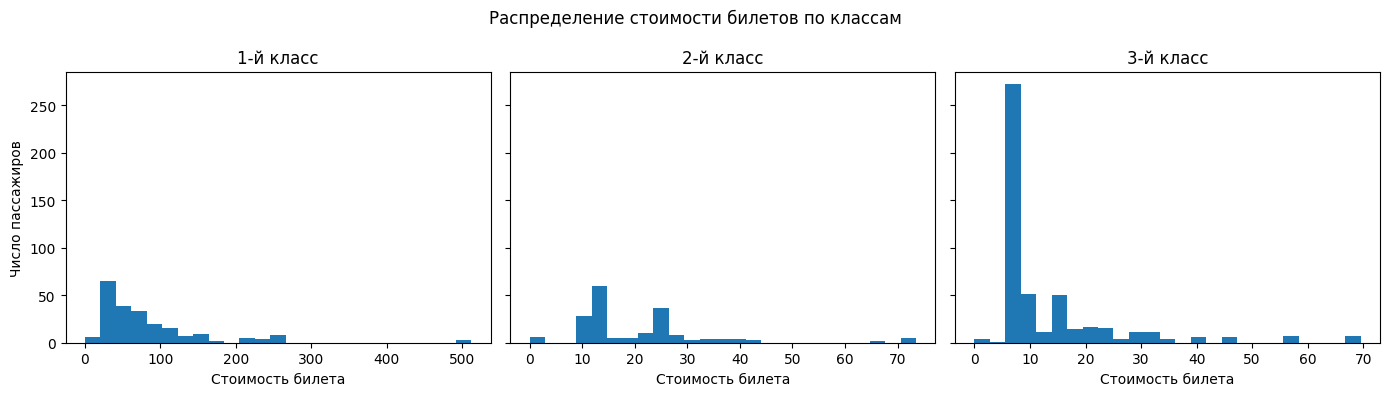

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, pclass in zip(axes, [1, 2, 3]):
    ax.hist(df.loc[df['Pclass'] == pclass, 'Fare'], bins=25)
    ax.set_title(f'{pclass}-й класс')
    ax.set_xlabel('Стоимость билета')
axes[0].set_ylabel('Число пассажиров')
fig.suptitle('Распределение стоимости билетов по классам')
plt.tight_layout()
plt.show()


3. Постройте зависимость цены от возраста пассажира

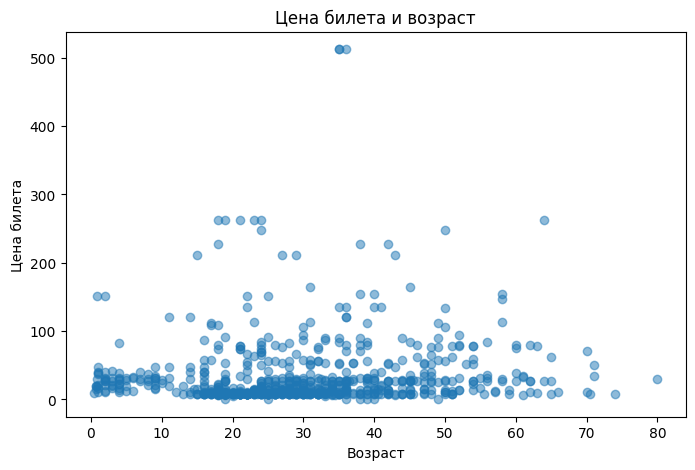

In [26]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Age'], df['Fare'], alpha=0.5)
plt.title('Цена билета и возраст')
plt.xlabel('Возраст')
plt.ylabel('Цена билета')
plt.show()


4. Постройте box plot отображающий распределение цен на билеты в разных классах

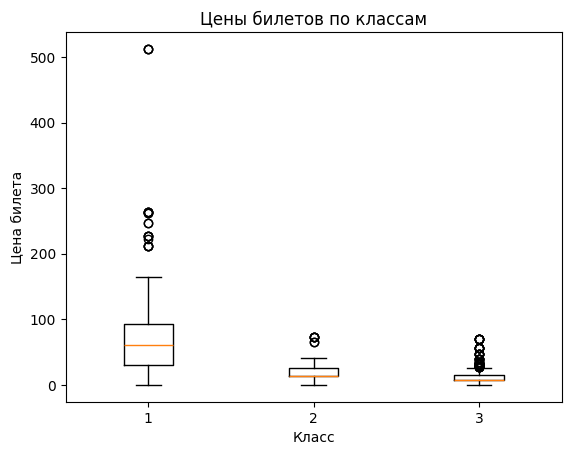

In [27]:
fares = [df.loc[df['Pclass'] == c, 'Fare'] for c in [1, 2, 3]]
plt.boxplot(fares, tick_labels=['1', '2', '3'])
plt.title('Цены билетов по классам')
plt.xlabel('Класс')
plt.ylabel('Цена билета')
plt.show()


5. Визуализируйте распределение долей выживших среди мужчин, женщин и детей(до 16 лет)

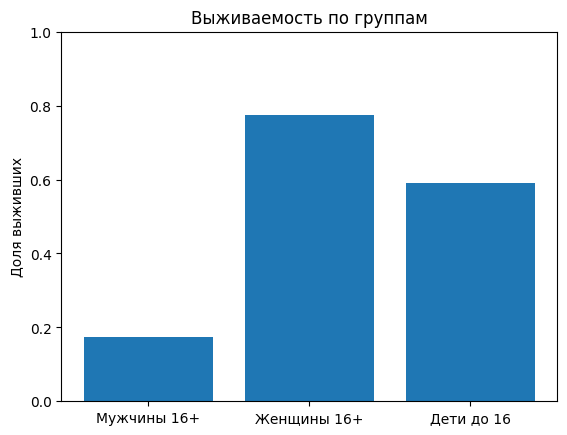

In [28]:
children = df['Age'] < 16
adults = df['Age'] >= 16
men = adults & (df['Sex'] == 'male')
women = adults & (df['Sex'] == 'female')
rates = [df.loc[men, 'Survived'].mean(),
         df.loc[women, 'Survived'].mean(),
         df.loc[children, 'Survived'].mean()]
plt.bar(['Мужчины 16+', 'Женщины 16+', 'Дети до 16'], rates)
plt.ylim(0, 1)
plt.ylabel('Доля выживших')
plt.title('Выживаемость по группам')
plt.show()


6. Сравните плотности распределения возростов выживших и умерших пассажиров, сделайте выводы

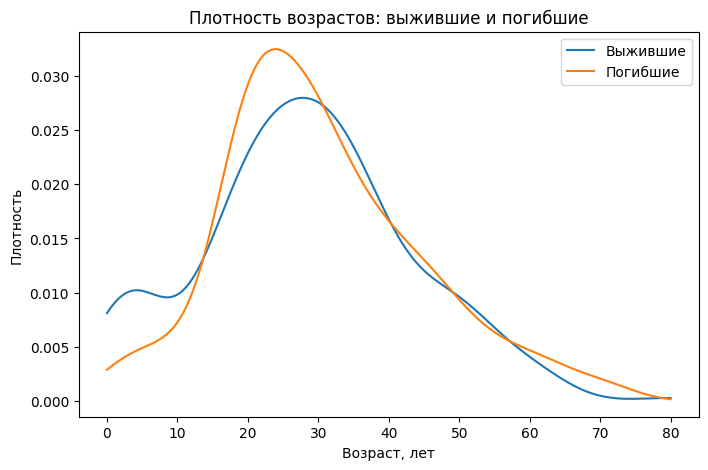

Вывод: распределения сильно перекрываются; одного возраста недостаточно для надёжного объяснения выживаемости.


In [29]:
from matplotlib.mlab import GaussianKDE

ages_survived = df.loc[df['Survived'] == 1, 'Age'].dropna()
ages_dead = df.loc[df['Survived'] == 0, 'Age'].dropna()
ages = np.linspace(0, df['Age'].max(), 200)
plt.figure(figsize=(8, 5))
plt.plot(ages, GaussianKDE(ages_survived)(ages), label='Выжившие')
plt.plot(ages, GaussianKDE(ages_dead)(ages), label='Погибшие')
plt.title('Плотность возрастов: выжившие и погибшие')
plt.xlabel('Возраст, лет')
plt.ylabel('Плотность')
plt.legend()
plt.show()
print('Вывод: распределения сильно перекрываются; одного возраста недостаточно для надёжного объяснения выживаемости.')


7. Постройте круговую диаграмму отображающую выживаемость мужчин и женщин в разных классах обслуживания(визуализация должна быть интуитивно понятная без объяснений, женщины и мужчины соответствующих классов объеденены визуально в одну группу и 2 подгруппы)*

\* Задание на доп. балл

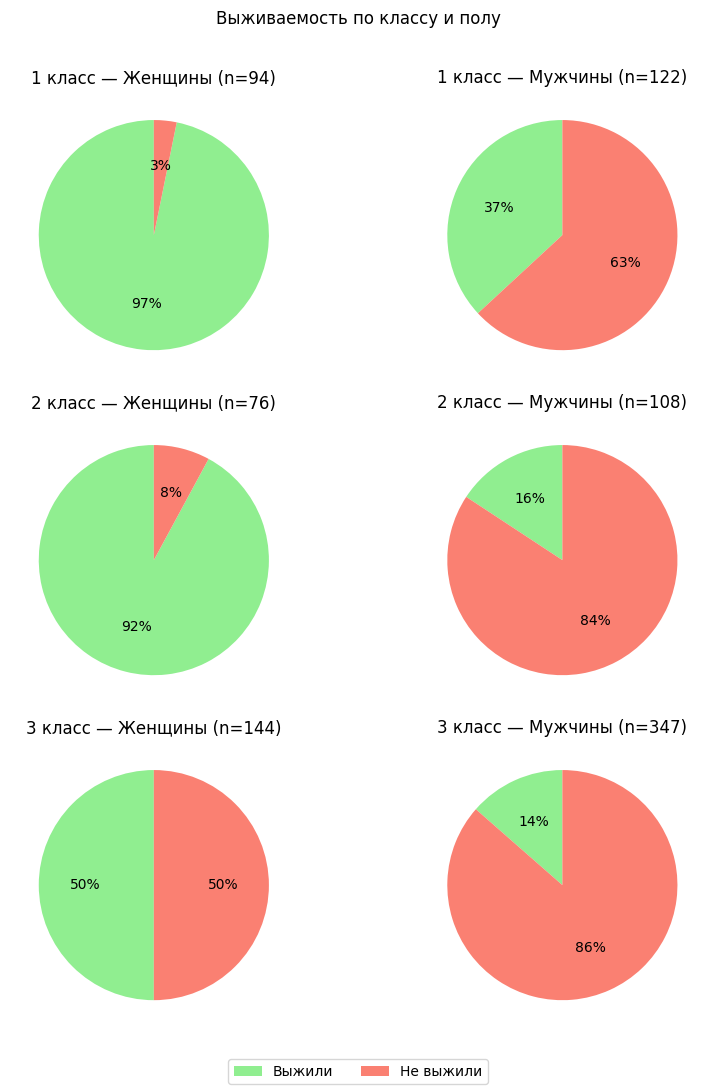

In [30]:
fig, axes = plt.subplots(3, 2, figsize=(9, 11))
for row, pclass in enumerate([1, 2, 3]):
    for col, (sex, label) in enumerate([('female', 'Женщины'), ('male', 'Мужчины')]):
        part = df[(df['Pclass'] == pclass) & (df['Sex'] == sex)]
        counts = part['Survived'].value_counts().reindex([1, 0], fill_value=0)
        axes[row, col].pie(counts, colors=['lightgreen', 'salmon'], autopct='%1.0f%%', startangle=90)
        axes[row, col].set_title(f'{pclass} класс — {label} (n={len(part)})')
fig.legend(['Выжили', 'Не выжили'], loc='lower center', ncol=2)
fig.suptitle('Выживаемость по классу и полу')
plt.tight_layout(rect=[0, 0.04, 1, 0.97])
plt.show()
